In [1]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.decomposition import PCA
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import time
from sklearn.metrics import f1_score

In [2]:
SEMENTE = 42
np.random.seed(SEMENTE)
here = os.getcwd()
data = pd.read_csv(os.path.join(here, "cenarioA_nominais_ordinais.csv"), sep=";", decimal=',')

In [4]:
def padronizar(X):
    X = np.asarray(X, dtype=float)
    N, D = X.shape
    Z = np.zeros((N, D))

    for j in range(D):
         mu_j = X[:, j].mean()
         s_j = X[:, j].std(ddof=1)
         Z[:, j] = (X[:, j] - mu_j) / s_j
    return Z

def ajustar_minmax(X_tr):
    X_tr = np.asarray(X_tr, dtype=float)
    minimo = X_tr.min(axis = 0)
    maximo = X_tr.max(axis = 0)
    faixa = np.where(maximo-minimo == 0, 1.0, maximo - minimo)
    return minimo, faixa

def aplicar_minmax(X_qualquer, minimo, faixa):
    X_qualquer = np.asarray(X_qualquer, dtype=float)
    return (X_qualquer - minimo)/faixa

def aplicar_pre_processamento_final(X_tr, X_te, norm, pca, std, n_componentes=0.95):
    X_tr_proc, X_te_proc = np.asarray(X_tr, dtype=float).copy(), np.asarray(X_te, dtype=float).copy()

    if std:
        scaler = StandardScaler()
        X_tr_proc = scaler.fit_transform(X_tr_proc)
        X_te_proc = scaler.transform(X_te_proc)
    elif pca:
        scaler = StandardScaler()
        X_tr_proc = scaler.fit_transform(X_tr_proc)
        X_te_proc = scaler.transform(X_te_proc)

        modelo_pca = PCA(n_components=n_componentes)
        X_tr_proc = modelo_pca.fit_transform(X_tr_proc)
        X_te_proc = modelo_pca.transform(X_te_proc)
    elif norm:
        minimo, faixa = ajustar_minmax(X_tr_proc)
        X_tr_proc = aplicar_minmax(X_tr_proc, minimo, faixa)
        X_te_proc = aplicar_minmax(X_te_proc, minimo, faixa)

    return X_tr_proc, X_te_proc

In [5]:
def distancia(A, q, metrica = "euclidiana", p = 3):
    A = np.asarray(A, dtype=float)
    dif  = (A-q)
    if metrica == "euclidiana":
        return np.sqrt(np.sum(dif ** 2, axis = 1))
    elif metrica == "manhattan":
        return np.sum(np.abs(dif), axis = 1)
    elif metrica == "chebyshev":
        return np.max(np.abs(dif), axis = 1)
    raise ValueError(f"Metrica desconhecida: {metrica}")

In [6]:
class KNN:
    def __init__(self, k = 5, metrica = "manhattan", ponderado = False, p = 3):
        self.K = k
        self.metrica = metrica
        self.ponderado = ponderado
        self.p = p

    def fit(self, X, y):
        self.X_treino = np.asarray(X, dtype=float)
        self.y_treino = np.asanyarray(y)
        self.classes = np.unique(y)
        return self

    def _classificar_um(self, q):
        d = distancia(self.X_treino, q, self.metrica, self.p)
        viz = np.argsort(d)[:self.K]

        if self.ponderado:
            peso = 1.0 / (d[viz] + 1e-10)
        else:
            peso = np.ones(self.K)

        votos = np.zeros(len(self.classes))
        for i, classe in enumerate(self.classes):
            mascara = self.y_treino[viz] == classe
            votos[i] = peso[mascara].sum()

        return self.classes[np.argmax(votos)]

    def predict(self, X):
        X = np.asarray(X, dtype = float)
        predicao = []
        for q in X:
            predicao.append(self._classificar_um(q))
        return np.array(predicao)

In [7]:
def matriz_confusao(y_real, y_pred, n_classes):
    M = np.zeros((n_classes, n_classes), dtype=int)
    for real, pred in zip(y_real, y_pred):
        M[real,pred] += 1
    return M

def relatorio_metricas(M):
    total = M.sum()
    acertos = np.trace(M)
    acuracia = acertos / total

    precisao, revocacao, f1 = [], [], []
    VP_lista, FP_lista, FN_lista = [], [], []

    for c in range(M.shape[0]):
        VP = M[c, c]
        FP = M[:, c].sum() - VP
        FN = M[c, :].sum() - VP

        VP_lista.append(VP)
        FP_lista.append(FP)
        FN_lista.append(FN)

        P = VP / (VP + FP) if (VP + FP) > 0 else 0.0
        R = VP / (VP + FN) if (VP + FN) > 0 else 0.0
        F = 2 * P * R / (P + R) if (P + R) > 0 else 0.0

        precisao.append(P)
        revocacao.append(R)
        f1.append(F)

    return {
        "VP_por_classe": np.array(VP_lista),
        "FP_por_classe": np.array(FP_lista),
        "FN_por_classe": np.array(FN_lista),
        "acuracia": acuracia,
        "precisao": np.array(precisao),
        "revocacao": np.array(revocacao),
        "f1": np.array(f1),
        "f1_macro": np.mean(f1),
        "acuracia_balanceada": np.mean(revocacao)
    }

In [ ]:
X = data.drop(columns="Target")
data['Target'] = OrdinalEncoder(categories = [['Dropout', 'Enrolled', 'Graduate']]).fit_transform(data[['Target']]).astype(int)
y = data['Target']

X_treino, X_teste, y_treino, y_test = train_test_split(X, y, test_size = 0.3, random_state=SEMENTE, stratify=y)

# separar 1000 amostras pra pedisao de 1000
X_1000 = np.asarray(X_teste, dtype=float)[:1000]

In [9]:
def valida_cruzada(X, y, k, metrica="manhattan", usar_pca=True, normalizar=True, padronizar=True, n_componentes=0.95):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)

    skf = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEMENTE)

    scores = []
    for idx_tr, idx_val in skf.split(X, y):
        Xtr, Xva = X[idx_tr], X[idx_val]
        ytr, yva = y[idx_tr], y[idx_val]

        if padronizar:
            scaler = StandardScaler()
            Xtr = scaler.fit_transform(Xtr)
            Xva = scaler.transform(Xva)
        elif usar_pca:
            scaler = StandardScaler()
            Xtr = scaler.fit_transform(Xtr)
            Xva = scaler.transform(Xva)
            pca = PCA(n_components=n_componentes)
            Xtr = pca.fit_transform(Xtr)
            Xva = pca.transform(Xva)
        elif normalizar:
            minimo_fold, faixa_fold = ajustar_minmax(X[idx_tr])
            Xtr = aplicar_minmax(Xtr, minimo_fold, faixa_fold)
            Xva = aplicar_minmax(Xva, minimo_fold, faixa_fold)

        modelo_fold = KNN(k=k, metrica=metrica)
        modelo_fold.fit(Xtr, ytr)
        yva_pred = modelo_fold.predict(Xva)

        f1 = f1_score(yva, yva_pred, labels=[0, 1, 2], average="macro", zero_division=0)
        scores.append(f1)

    return np.mean(scores), np.std(scores, ddof=1)

In [ ]:
cenarios_distancias = [
    {"nome": "Manhattan_Sem_pre_processamento", "metrica": "manhattan", "norm": False, "pca": False, "std": False},
    {"nome": "Manhattan_Normalizacao",          "metrica": "manhattan", "norm": True,  "pca": False, "std": False},
    {"nome": "Manhattan_PCA",                   "metrica": "manhattan", "norm": False, "pca": True,  "std": False},
    {"nome": "Manhattan_Padronizacao",          "metrica": "manhattan", "norm": False, "pca": False, "std": True},

    {"nome": "Euclidiana_Sem_pre_processamento", "metrica": "euclidiana", "norm": False, "pca": False, "std": False},
    {"nome": "Euclidiana_Normalizacao",          "metrica": "euclidiana", "norm": True,  "pca": False, "std": False},
    {"nome": "Euclidiana_PCA",                   "metrica": "euclidiana", "norm": False, "pca": True,  "std": False},
    {"nome": "Euclidiana_Padronizacao",          "metrica": "euclidiana", "norm": False, "pca": False, "std": True}
]


Executando cenário: Manhattan_Sem_pre_processamento
Melhor k encontrado: 5 (F1-macro CV: 0.4596)


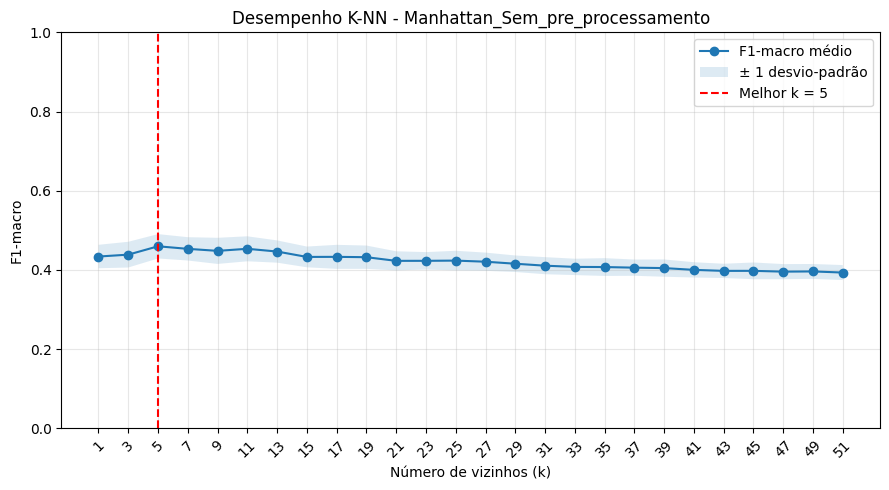


Relatório de Métricas no Teste:
  Classe  VP  FP  FN  Precisão  Revocação       F1
 Dropout 214 191 205  0.528395   0.510740 0.519417
Enrolled  48 119 177  0.287425   0.213333 0.244898
Graduate 416 275 203  0.602026   0.672052 0.635115

Acurácia: 0.5368
F1-macro: 0.4665
Desvio-padrão: 0.0308
Acurácia balanceada: 0.4654

Tempo Treino: 0.17 ms
Tempo Predição (Todos): 499.68 ms
Tempo Predição (1000 amostras): 435.89 ms
Concordância com Scikit-Learn: 99.29%


Executando cenário: Manhattan_Normalizacao


In [ ]:
ks = list(range(1, 52, 2))
resultados_finais = []

for c in cenarios_distancias:
    print(f"\n{'='*70}")
    print(f"Executando cenário: {c['nome']}")
    print(f"{'='*70}")

    resultados_cv = [
        valida_cruzada(
            X_treino, y_treino, k,
            metrica=c["metrica"], usar_pca=c["pca"],
            normalizar=c["norm"], padronizar=c["std"]
        ) for k in ks
    ]

    medias_cv = [resultado[0] for resultado in resultados_cv]
    desvios_cv = [resultado[1] for resultado in resultados_cv]

    indice_melhor = int(np.argmax(medias_cv))
    melhor_k = ks[indice_melhor]

    print(f"Melhor k encontrado: {melhor_k} (F1-macro CV: {medias_cv[indice_melhor]:.4f})")

    plt.figure(figsize=(9, 5))
    plt.plot(ks, medias_cv, marker="o", label="F1-macro médio")
    plt.fill_between(ks, np.array(medias_cv) - np.array(desvios_cv),
                     np.array(medias_cv) + np.array(desvios_cv), alpha=0.15, label="± 1 desvio-padrão")
    plt.axvline(melhor_k, color="red", linestyle="--", label=f"Melhor k = {melhor_k}")
    plt.xlabel("Número de vizinhos (k)")
    plt.ylabel("F1-macro")
    plt.title(f"Desempenho K-NN - {c['nome']}")
    plt.xticks(ks, rotation=45)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"desempenho_{c['nome']}.png", dpi=300)
    plt.show()

    X_tr_final, X_te_final = aplicar_pre_processamento_final(
        X_treino, X_teste, norm=c["norm"], pca=c["pca"], std=c["std"]
    )
    _, X_1000_final = aplicar_pre_processamento_final(
        X_treino, X_1000, norm=c["norm"], pca=c["pca"], std=c["std"]
    )

    t0_treino = time.perf_counter()
    modelo_final = KNN(k=melhor_k, metrica=c["metrica"])
    modelo_final.fit(X_tr_final, y_treino)
    tempo_treino_ms = (time.perf_counter() - t0_treino) * 1000

    t0_pred = time.perf_counter()
    y_pred = modelo_final.predict(X_te_final)
    tempo_pred_ms = (time.perf_counter() - t0_pred) * 1000

    t0_pred_1000 = time.perf_counter()
    _ = modelo_final.predict(X_1000_final)
    tempo_pred_1000_ms = (time.perf_counter() - t0_pred_1000) * 1000

    M = matriz_confusao(y_test, y_pred, 3)
    resultado_metricas = relatorio_metricas(M)

    classes = ["Dropout", "Enrolled", "Graduate"]
    tabela = pd.DataFrame({
        "Classe": classes,
        "VP": resultado_metricas["VP_por_classe"],
        "FP": resultado_metricas["FP_por_classe"],
        "FN": resultado_metricas["FN_por_classe"],
        "Precisão": resultado_metricas["precisao"],
        "Revocação": resultado_metricas["revocacao"],
        "F1": resultado_metricas["f1"]
    })
    print("\nRelatório de Métricas no Teste:")
    print(tabela.to_string(index=False))

    print(f"\nAcurácia: {resultado_metricas['acuracia']:.4f}")
    print(f"F1-macro: {resultado_metricas['f1_macro']:.4f}")
    print(f"Desvio-padrão: {desvios_cv[indice_melhor]:.4f}")
    print(f"Acurácia balanceada: {resultado_metricas['acuracia_balanceada']:.4f}\n")

    metrica_sklearn = "euclidean" if c["metrica"] == "euclidiana" else c["metrica"]
    ref_sklearn = KNeighborsClassifier(n_neighbors=melhor_k, metric=metrica_sklearn)

    ref_sklearn.fit(X_tr_final, y_treino)
    y_ref = ref_sklearn.predict(X_te_final)
    proporcao_iguais = np.mean(y_ref == y_pred)

    print(f"Tempo Treino: {tempo_treino_ms:.2f} ms")
    print(f"Tempo Predição (Todos): {tempo_pred_ms:.2f} ms")
    print(f"Tempo Predição (1000 amostras): {tempo_pred_1000_ms:.2f} ms")
    print(f"Concordância com Scikit-Learn: {proporcao_iguais * 100:.2f}%\n")

    resultados_finais.append({
        "Cenário": c["nome"],
        "Melhor K": melhor_k,
        "Acurácia": resultado_metricas['acuracia'],
        "F1-Macro": resultado_metricas['f1_macro'],
        "Treino (ms)": round(tempo_treino_ms, 2),
        "Predição (ms)": round(tempo_pred_ms, 2),
        "Pred 1000 (ms)": round(tempo_pred_1000_ms, 2)
    })

In [ ]:
resumo_df = pd.DataFrame(resultados_finais)

resumo_df = resumo_df.sort_values(by="F1-Macro", ascending=False).reset_index(drop=True)

print("RESUMO CONSOLIDADO DE TODOS OS CENÁRIOS (Ordenado por F1-Macro):")
display(resumo_df)